# Volume I dataset: overview and structure checks

Placeholder notebook (to be extended). Loads the reviewed dataset from `output/volume1/dataset/` (run `make dataset` first) and checks that the unusual printed layout, especially the 800 m arc, came out as a regular grid.

Status values: `value`, `not_measurable` (printed blank: "no measurable concentration", printed pp. 79 and 193), `missing` (printed M).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))  # notebooks/ (for pgdata)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import pgdata
arcs, towers = pgdata.arcs(), pgdata.towers()
len(arcs), len(towers)

(30510, 2808)

## Cell states

In [2]:
pd.concat({"arcs": arcs["status"].value_counts(), "towers": towers["status"].value_counts()}, axis=1)

,arcs,towers
not_measurable,22306,1700
value,8173,1096
missing,31,12
unread,0,0


## Grid structure per arc

Inner arcs: posts 1–91 at 2°. 800 m arc: posts 1–181 at 1°. Same half circle, west (270°) through north to east (90°).

In [3]:
arcs.groupby("arc_m").agg(posts=("post", "nunique"), first_post=("post", "min"), last_post=("post", "max"),
                           bearing_min=("bearing_unwrapped", "min"), bearing_max=("bearing_unwrapped", "max"),
                           runs=("run", "nunique"), cells=("cell_id", "size"),
                           values=("status", lambda s: (s == "value").sum()))

,posts,first_post,last_post,bearing_min,bearing_max,runs,cells,values
arc_m,,,,,,,,
50,91,1,91,270,450,68,5094,2054
100,91,1,91,270,450,68,5094,1713
200,91,1,91,270,450,68,5094,1443
400,91,1,91,270,450,68,5094,1174
800,181,1,181,270,450,68,10134,1789


In [4]:
# every (run, arc, post) appears at most once; posts per run and arc (a single printed half gives ~45/46 or ~90/91)
assert not arcs.duplicated(["run", "arc_m", "post"]).any()
arcs.groupby(["arc_m", "run"])["post"].nunique().groupby("arc_m").value_counts().unstack(fill_value=0)

post,45,46,90,91,181
arc_m,,,,,
50,14,10,0,44,0
100,14,10,0,44,0
200,14,10,0,44,0
400,14,10,0,44,0
800,0,0,14,10,44


In [5]:
# towers: 6 towers x 9 heights for every run with tower data
assert not towers.duplicated(["run", "tower", "height_m"]).any()
towers.groupby("run").size().value_counts()

54    52
dtype: int64

## Coverage: printed values per run and arc

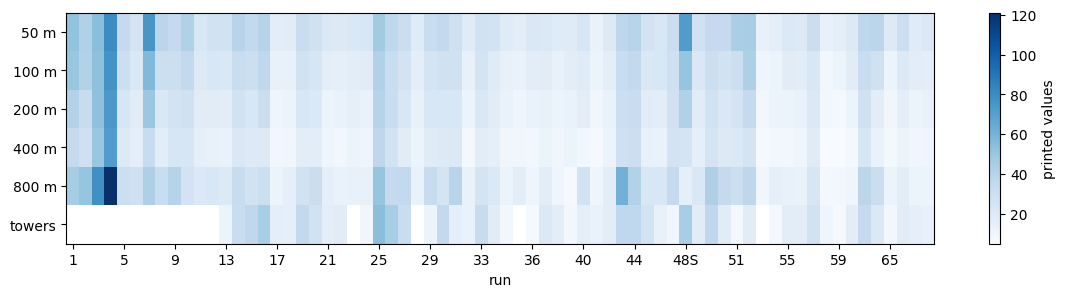

In [6]:
cov = (pd.concat([arcs.assign(group=arcs["arc_m"].astype(str) + " m"), towers.assign(group="towers")], ignore_index=True)
       .assign(is_value=lambda d: d["status"] == "value")
       .pivot_table(index="group", columns="run", values="is_value", aggfunc="sum"))
cov = cov[pgdata.runs_in_order(arcs)].reindex(["50 m", "100 m", "200 m", "400 m", "800 m", "towers"])
fig, ax = plt.subplots(figsize=(14, 3))
im = ax.imshow(cov.to_numpy(dtype=float), aspect="auto", cmap="Blues")
ax.set_yticks(range(len(cov.index)), cov.index); ax.set_xticks(range(0, cov.shape[1], 4), cov.columns[::4])
ax.set_xlabel("run"); fig.colorbar(im, label="printed values"); plt.show()